In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv('data.txt', sep=';',names=['text','emotion'])
df

,text,emotion
0,i didnt feel humiliated,sadness
1,i can go from feeling so hopeless to so damned...,sadness
2,im grabbing a minute to post i feel greedy wrong,anger
3,i am ever feeling nostalgic about the fireplac...,love
4,i am feeling grouchy,anger
...,...,...
15995,i just had a very brief time in the beanbag an...,sadness
15996,i am now turning and i feel pathetic that i am...,sadness
15997,i feel strong and good overall,joy
15998,i feel like this was such a rude comment and i...,anger


In [3]:
df.isnull().sum()

text       0
emotion    0
dtype: int64

In [4]:
emotion_arr = df['emotion'].unique()
emotion_arr

<ArrowStringArray>
['sadness', 'anger', 'love', 'surprise', 'fear', 'joy']
Length: 6, dtype: str

In [5]:
i=0
emotion_numbers={}
for emo in emotion_arr:
    emotion_numbers[emo]=i
    print(emotion_numbers)
    i+=1
df['emotion'] = df['emotion'].replace(emotion_numbers).astype(int)
df

{'sadness': 0}
{'sadness': 0, 'anger': 1}
{'sadness': 0, 'anger': 1, 'love': 2}
{'sadness': 0, 'anger': 1, 'love': 2, 'surprise': 3}
{'sadness': 0, 'anger': 1, 'love': 2, 'surprise': 3, 'fear': 4}
{'sadness': 0, 'anger': 1, 'love': 2, 'surprise': 3, 'fear': 4, 'joy': 5}


,text,emotion
0,i didnt feel humiliated,0
1,i can go from feeling so hopeless to so damned...,0
2,im grabbing a minute to post i feel greedy wrong,1
3,i am ever feeling nostalgic about the fireplac...,2
4,i am feeling grouchy,1
...,...,...
15995,i just had a very brief time in the beanbag an...,0
15996,i am now turning and i feel pathetic that i am...,0
15997,i feel strong and good overall,5
15998,i feel like this was such a rude comment and i...,1


In [6]:
df['text'] = df['text'].apply(lambda x: x.lower())

In [7]:
#removing punctuation
import string
def remove_punc(txt):
    return txt.translate(str.maketrans('','',string.punctuation))


In [8]:
df['text'] = df['text'].apply(remove_punc)

In [9]:
def remove_num(txt):
    new = ''
    for i in txt:
        if not i.isdigit():
            new = new + i
    return new
df['text'] = df['text'].apply(remove_num)
df

,text,emotion
0,i didnt feel humiliated,0
1,i can go from feeling so hopeless to so damned...,0
2,im grabbing a minute to post i feel greedy wrong,1
3,i am ever feeling nostalgic about the fireplac...,2
4,i am feeling grouchy,1
...,...,...
15995,i just had a very brief time in the beanbag an...,0
15996,i am now turning and i feel pathetic that i am...,0
15997,i feel strong and good overall,5
15998,i feel like this was such a rude comment and i...,1


In [10]:
def remove_emojis(txt):
    new = ""
    for i in txt:
        if i.isascii():
            new += i
    return new

df['text'] = df['text'].apply(remove_emojis)

In [11]:
import nltk
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize

In [12]:
nltk.download('punkt')
nltk.download('stopwords')

[nltk_data] Downloading package punkt to
[nltk_data]     C:\Users\Ahnaf\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\Ahnaf\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\Ahnaf\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


True

In [13]:
stop_words= set(stopwords.words('english'))


In [14]:
df.loc[1]['text']

'i can go from feeling so hopeless to so damned hopeful just from being around someone who cares and is awake'

In [15]:
def remove(txt):
    words = txt.split()
    cleaned = []
    for i in words:
        if not i in stop_words:
            cleaned.append(i)
    return ' '.join(cleaned)
df['text'] = df['text'].apply(remove)

In [16]:
df.loc[1]['text']

'go feeling hopeless damned hopeful around someone cares awake'

In [17]:
df.head()

,text,emotion
0,didnt feel humiliated,0
1,go feeling hopeless damned hopeful around some...,0
2,im grabbing minute post feel greedy wrong,1
3,ever feeling nostalgic fireplace know still pr...,2
4,feeling grouchy,1


In [18]:
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import classification_report,accuracy_score
from sklearn.feature_extraction.text import TfidfVectorizer,CountVectorizer

In [19]:
tfidf = TfidfVectorizer()
bagofWords=CountVectorizer(ngram_range=(1,1))


In [20]:
X_train, X_test, y_train, y_test = train_test_split(
df['text'],df['emotion'], test_size=0.20, random_state=42)
y_train

676      5
12113    0
7077     2
13005    0
12123    1
        ..
13418    4
5390     2
860      0
15795    0
7270     1
Name: emotion, Length: 12800, dtype: int64

In [21]:
X_train_bow=bagofWords.fit_transform(X_train)
X_test_bow = bagofWords.transform(X_test)

X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)

In [22]:
#naive bayes trying
naive_model=MultinomialNB()
naive_model.fit(X_train_bow,y_train)
pred_from_bow=naive_model.predict(X_test_bow)
pred_from_bow
accuracy_score(y_test,pred_from_bow)

0.768125

In [23]:
naive_model.fit(X_train_tfidf,y_train)
pred_from_tfidf=naive_model.predict(X_test_tfidf)
accuracy_score(y_test,pred_from_tfidf)

0.6609375

In [24]:
from sklearn.linear_model import LogisticRegression
logistic_model=LogisticRegression(max_iter=1000)
logistic_model.fit(X_train_tfidf,y_train)


,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is '

In [25]:
log_pred=logistic_model.predict(X_test_tfidf)
accuracy_score(log_pred,y_test)

0.8628125

In [26]:
from sklearn.svm import LinearSVC
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

svm_model = LinearSVC()
svm_pred = svm_model.fit(X_train_tfidf, y_train).predict(X_test_tfidf)

models = {
    'Naive Bayes (BOW)': pred_from_bow,
    'Naive Bayes (TF-IDF)': pred_from_tfidf,
    'Logistic Regression (TF-IDF)': log_pred,
    'SVM (TF-IDF)': svm_pred,
}

comparison = pd.DataFrame([
    {
        'Model': name,
        'Accuracy': accuracy_score(y_test, predictions),
        'Precision': precision_score(y_test, predictions, average='weighted', zero_division=0),
        'Recall': recall_score(y_test, predictions, average='weighted', zero_division=0),
        'F1 Score': f1_score(y_test, predictions, average='weighted', zero_division=0),
    }
    for name, predictions in models.items()
]).sort_values('F1 Score', ascending=False).reset_index(drop=True)

comparison

,Model,Accuracy,Precision,Recall,F1 Score
0,SVM (TF-IDF),0.891875,0.891110,0.891875,0.890587
1,Logistic Regression (TF-IDF),0.862812,0.867114,0.862812,0.857403
2,Naive Bayes (BOW),0.768125,0.799918,0.768125,0.737296
3,Naive Bayes (TF-IDF),0.660937,0.762364,0.660937,0.582596


## 5. Hyperparameter Tuning & Stratified Cross-Validation (CV)

To make our sentiment analysis robust and prevent overfitting to a single train-test split, we apply:
1. **Stratified 5-Fold Cross-Validation (`StratifiedKFold`)**: Preserves class distribution across all 5 folds, critical for imbalanced classes (e.g. *surprise* vs *joy*).
2. **Leak-Free ML Pipelines (`Pipeline`)**: Combines feature extraction (CountVectorizer/TfidfVectorizer) and model estimators. Fitting occurs strictly inside each CV training fold, avoiding data leakage.
3. **Hyperparameter Optimization (`GridSearchCV`)**: Searches optimal n-gram ranges, sublinear TF scaling, alpha smoothing (Naive Bayes), and regularization $C$ (Logistic Regression & LinearSVC).


In [27]:
from sklearn.model_selection import StratifiedKFold, GridSearchCV, cross_val_score
from sklearn.pipeline import Pipeline
import time

# 5-fold Stratified Cross-Validation setup
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# Define pipelines and hyperparameter grids
param_grids = {
    'Naive Bayes (BOW)': (
        Pipeline([
            ('vec', CountVectorizer()),
            ('clf', MultinomialNB())
        ]),
        {
            'vec__ngram_range': [(1, 1), (1, 2)],
            'vec__min_df': [1, 2, 3],
            'clf__alpha': [0.1, 0.5, 1.0, 1.5]
        }
    ),
    'Naive Bayes (TF-IDF)': (
        Pipeline([
            ('vec', TfidfVectorizer()),
            ('clf', MultinomialNB())
        ]),
        {
            'vec__ngram_range': [(1, 1), (1, 2)],
            'vec__sublinear_tf': [True, False],
            'clf__alpha': [0.1, 0.25, 0.5, 1.0]
        }
    ),
    'Logistic Regression (TF-IDF)': (
        Pipeline([
            ('vec', TfidfVectorizer()),
            ('clf', LogisticRegression(max_iter=1000, random_state=42))
        ]),
        {
            'vec__ngram_range': [(1, 1), (1, 2)],
            'vec__sublinear_tf': [True, False],
            'clf__C': [1.0, 2.5, 5.0, 10.0]
        }
    ),
    'SVM (TF-IDF)': (
        Pipeline([
            ('vec', TfidfVectorizer()),
            ('clf', LinearSVC(random_state=42, dual='auto'))
        ]),
        {
            'vec__ngram_range': [(1, 1), (1, 2)],
            'vec__sublinear_tf': [True, False],
            'clf__C': [0.5, 1.0, 1.5, 2.0]
        }
    )
}


In [28]:
tuning_results = []
fitted_grids = {}

print("Running 5-Fold Stratified Cross-Validation & Hyperparameter Tuning...")
for name, (pipeline, params) in param_grids.items():
    start_time = time.time()
    grid = GridSearchCV(
        pipeline,
        params,
        cv=cv,
        scoring='f1_weighted',
        n_jobs=-1,
        refit=True
    )
    grid.fit(X_train, y_train)
    elapsed = time.time() - start_time
    
    fitted_grids[name] = grid
    best_pipe = grid.best_estimator_
    y_pred = best_pipe.predict(X_test)
    
    cv_scores = cross_val_score(best_pipe, X_train, y_train, cv=cv, scoring='f1_weighted', n_jobs=-1)
    
    tuning_results.append({
        'Model': name,
        'Best Parameters': grid.best_params_,
        'Mean CV F1': np.mean(cv_scores),
        'CV F1 Std': np.std(cv_scores),
        'Test Accuracy': accuracy_score(y_test, y_pred),
        'Test F1 (Weighted)': f1_score(y_test, y_pred, average='weighted', zero_division=0),
        'Test Precision': precision_score(y_test, y_pred, average='weighted', zero_division=0),
        'Test Recall': recall_score(y_test, y_pred, average='weighted', zero_division=0),
        'Tuning Time (s)': round(elapsed, 2)
    })
    print(f"✓ {name}: Best CV F1 = {np.mean(cv_scores):.4f} (±{np.std(cv_scores):.4f}) | Test Acc = {accuracy_score(y_test, y_pred):.4f} in {elapsed:.1f}s")


Running 5-Fold Stratified Cross-Validation & Hyperparameter Tuning...
✓ Naive Bayes (BOW): Best CV F1 = 0.8452 (±0.0052) | Test Acc = 0.8603 in 10.9s
✓ Naive Bayes (TF-IDF): Best CV F1 = 0.7249 (±0.0037) | Test Acc = 0.7559 in 3.6s
✓ Logistic Regression (TF-IDF): Best CV F1 = 0.8845 (±0.0035) | Test Acc = 0.8919 in 115.2s
✓ SVM (TF-IDF): Best CV F1 = 0.9020 (±0.0037) | Test Acc = 0.9025 in 7.9s


In [29]:
cv_summary_df = pd.DataFrame(tuning_results).sort_values('Mean CV F1', ascending=False).reset_index(drop=True)
cv_summary_df


,Model,Best Parameters,Mean CV F1,CV F1 Std,Test Accuracy,Test F1 (Weighted),Test Precision,Test Recall,Tuning Time (s)
0,SVM (TF-IDF),"{'clf__C': 2.0, 'vec__ngram_range': (1, 2), 'v...",0.902028,0.003715,0.902500,0.901741,0.901662,0.902500,7.92
1,Logistic Regression (TF-IDF),"{'clf__C': 10.0, 'vec__ngram_range': (1, 2), '...",0.884515,0.003467,0.891875,0.889967,0.891142,0.891875,115.25
2,Naive Bayes (BOW),"{'clf__alpha': 0.5, 'vec__min_df': 3, 'vec__ng...",0.845183,0.005153,0.860313,0.857360,0.857867,0.860313,10.93
3,Naive Bayes (TF-IDF),"{'clf__alpha': 0.1, 'vec__ngram_range': (1, 2)...",0.724886,0.003714,0.755938,0.724117,0.796174,0.755938,3.63


### 6. Best Model Selection & In-Depth Evaluation
We automatically select the champion model based on the highest 5-Fold Cross-Validation F1 score.
This model is evaluated with a full classification report, confusion matrix, and saved for inference.


In [30]:
# Automatically select best model based on Mean CV F1
best_model_row = cv_summary_df.iloc[0]
best_model_name = best_model_row['Model']
best_grid = fitted_grids[best_model_name]
best_model_pipeline = best_grid.best_estimator_

print(f"🏆 BEST MODEL SELECTED: {best_model_name}")
print(f"• Mean 5-Fold CV F1 Score: {best_model_row['Mean CV F1']:.4f} (±{best_model_row['CV F1 Std']:.4f})")
print(f"• Test Accuracy:           {best_model_row['Test Accuracy']:.4f}")
print(f"• Test Weighted F1:        {best_model_row['Test F1 (Weighted)']:.4f}")
print(f"• Optimal Hyperparameters: {best_model_row['Best Parameters']}")


🏆 BEST MODEL SELECTED: SVM (TF-IDF)
• Mean 5-Fold CV F1 Score: 0.9020 (±0.0037)
• Test Accuracy:           0.9025
• Test Weighted F1:        0.9017
• Optimal Hyperparameters: {'clf__C': 2.0, 'vec__ngram_range': (1, 2), 'vec__sublinear_tf': True}


=== Detailed Classification Report: SVM (TF-IDF) ===
              precision    recall  f1-score   support

     sadness     0.9367    0.9387    0.9377       946
       anger     0.8939    0.8876    0.8907       427
        love     0.8448    0.7905    0.8168       296
    surprise     0.8317    0.7434    0.7850       113
        fear     0.8724    0.8438    0.8579       397
         joy     0.9081    0.9481    0.9276      1021

    accuracy                         0.9025      3200
   macro avg     0.8812    0.8587    0.8693      3200
weighted avg     0.9017    0.9025    0.9017      3200



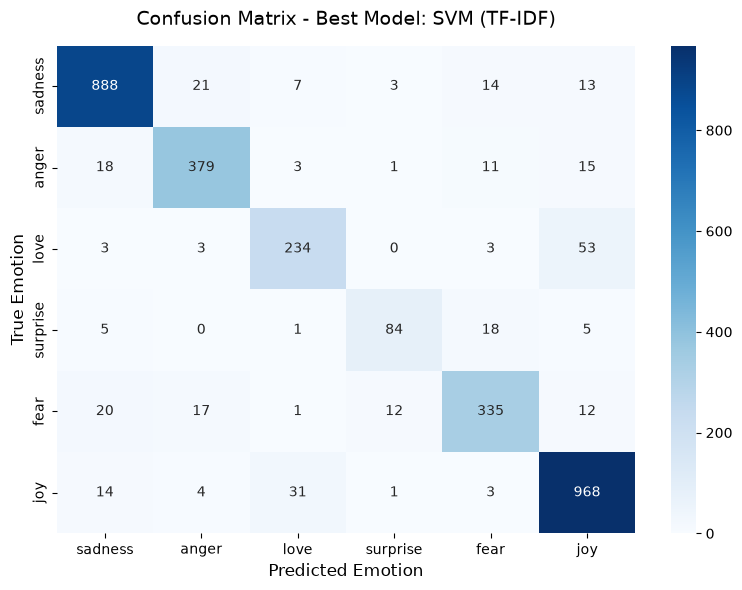

In [31]:
from sklearn.metrics import classification_report, confusion_matrix

y_pred_best = best_model_pipeline.predict(X_test)
label_names = [k for k, v in sorted(emotion_numbers.items(), key=lambda item: item[1])]

print(f"=== Detailed Classification Report: {best_model_name} ===")
print(classification_report(y_test, y_pred_best, target_names=label_names, digits=4))

# Confusion Matrix Heatmap
plt.figure(figsize=(8, 6))
cm = confusion_matrix(y_test, y_pred_best)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=label_names, yticklabels=label_names)
plt.title(f'Confusion Matrix - Best Model: {best_model_name}', fontsize=14, pad=15)
plt.xlabel('Predicted Emotion', fontsize=12)
plt.ylabel('True Emotion', fontsize=12)
plt.tight_layout()
plt.show()


In [33]:
import joblib

# Export best pipeline for production / Streamlit
joblib.dump(best_model_pipeline, 'best_sentiment_model.pkl')
print("✓ Saved best model pipeline to 'best_sentiment_model.pkl'")

# Test on live sample texts
id_to_emotion = {v: k for k, v in emotion_numbers.items()}
sample_sentences = [
    "I am feeling absolutely ecstatic and thrilled about this milestone!",
    "I'm terrified of what might happen next, everything feels uncertain.",
    "This is so unfair, it makes my blood boil with rage.",
    "I've been feeling deeply depressed and lonely all week.",
    "I love spending quiet evenings by the fire with family.",
    "Wow, I really did not expect that outcome at all!"
]

print("\n--- Live Inference with Best Model ---")
for text in sample_sentences:
    cleaned = text.lower()
    cleaned = remove_punc(cleaned)
    cleaned = remove_num(cleaned)
    cleaned = remove_emojis(cleaned)
    cleaned = remove(cleaned)
    pred_label = best_model_pipeline.predict([cleaned])[0]
    pred_emotion = id_to_emotion[pred_label]
    print(f'Text: "{text}"')
    print(f'Predicted Emotion: {pred_emotion.upper()}\n')


✓ Saved best model pipeline to 'best_sentiment_model.pkl'

--- Live Inference with Best Model ---
Text: "I am feeling absolutely ecstatic and thrilled about this milestone!"
Predicted Emotion: JOY

Text: "I'm terrified of what might happen next, everything feels uncertain."
Predicted Emotion: FEAR

Text: "This is so unfair, it makes my blood boil with rage."
Predicted Emotion: JOY

Text: "I've been feeling deeply depressed and lonely all week."
Predicted Emotion: SADNESS

Text: "I love spending quiet evenings by the fire with family."
Predicted Emotion: ANGER

Text: "Wow, I really did not expect that outcome at all!"
Predicted Emotion: SADNESS

